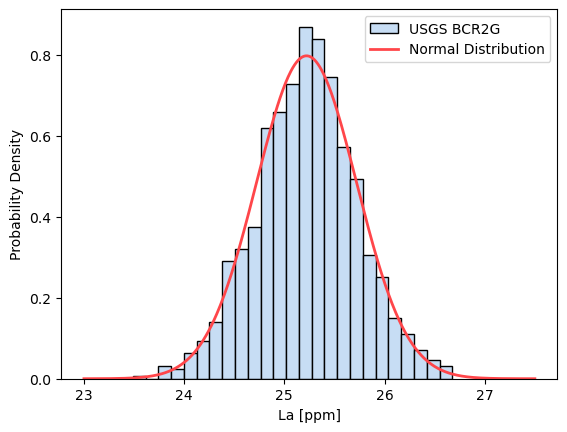

In [ ]:
import pandas as pd  # untuk membaca dan mengolah data (Excel)
import scipy.stats as stats # untuk fungsi statistik (distribusi normal, dll)
import matplotlib.pyplot as plt  # untuk membuat grafik
import numpy as np # untuk operasi numerik

my_dataset = pd.read_excel('USGS_BCR2G.xls', sheet_name='Sheet1') # membaca data dari file Excel (sheet 'Sheet1')

fig, ax = plt.subplots() # membuat figure dan axis untuk plotting
ax.hist(my_dataset.La, bins='auto', density=True, edgecolor='#000000', color='#c7ddf4', label="USGS BCR2G")
# ax.hist(my_dataset.La, 
# bins='auto', 
# density=True, 
# edgecolor='#000000', 
# color='#c7ddf4', 
# label="USGS BCR2G")  
# membuat histogram:
# bins='auto' → jumlah interval otomatis
# density=True → diubah jadi distribusi probabilitas (bukan frekuensi)
# edgecolor → warna garis tepi
# color → warna isi histogram

ax.set_xlabel("La [ppm]")
ax.set_ylabel("Probability Density")

x = np.linspace(23,27.5,500) # membuat 500 titik data dari 23 sampai 27.5 untuk kurva
pdf = stats.norm(loc=my_dataset.La.mean(), scale=my_dataset.La.std()).pdf(x)
# membuat fungsi distribusi normal (PDF):
# loc → mean (rata-rata data)
# scale → standar deviasi data
# .pdf(x) → nilai probabilitas untuk setiap x

ax.plot(x,pdf, linewidth=2, color='#ff464a', label='Normal Distribution') # menggambar kurva distribusi normal di atas histogram

ax.legend()

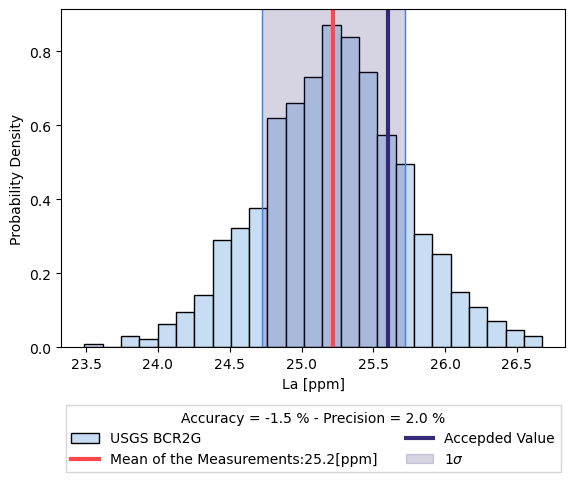

In [ ]:
my_mean = my_dataset.La.mean()  # menghitung rata-rata (mean) dari data La
R = 25.6 # nilai acuan (reference / accepted value)
accuracy = 100 * (my_mean - R) / R # menghitung akurasi (% selisih terhadap nilai acuan)
my_std = my_dataset.La.std() # menghitung standar deviasi data
precision = 100 * my_std / R # menghitung presisi (% penyebaran data terhadap nilai acuan)

fig, ax = plt.subplots(figsize=(6,5)) # membuat figure dengan ukuran 6x5 inci
ax.hist(my_dataset.La, bins = 'auto', density = True, edgecolor = '#000000', color = '#c7ddf4', label = 'USGS BCR2G') # membuat histogram distribusi data
ax.set_xlabel('La [ppm]')
ax.set_ylabel('Probability Density')

ax.axvline(x=my_dataset.La.mean(), color='#ff464a', linewidth=3, label='Mean of the Measurements:' + str(round(my_mean, 1)) + '[ppm]')# garis vertikal untuk nilai rata-rata
ax.axvline(x = R, color='#342a77', linewidth=3, label='Accepded Value') # garis vertikal untuk nilai acuan

ax.axvline(x = my_mean - my_std, color = '#4881e9', linewidth = 1) # batas bawah 1 standar deviasi (mean - std)
ax.axvline(x = my_mean + my_std, color = '#4881e9', linewidth = 1) # batas atas 1 standar deviasi (mean + std)
ax.axvspan(my_mean - my_std,  my_mean + my_std, alpha = 0.2, color = '#342a77', label = r'$1\sigma$') # area bayangan antara (mean - std) dan (mean + std)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), fancybox=False, shadow=False, ncol=2, title = 'Accuracy = {:.1f} % - Precision = {:.1f} %'.format(accuracy, precision)) # menampilkan legenda + menambahkan informasi akurasi & presisi di judul legenda

fig.tight_layout() # merapikan layout agar tidak bertumpuk


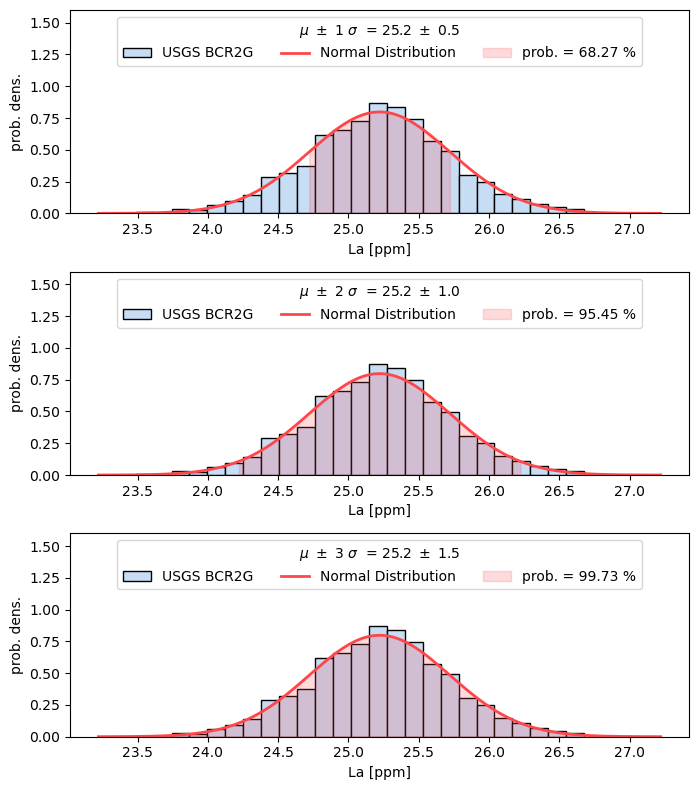

In [ ]:
import numpy as np  # untuk operasi numerik (array, perhitungan)
import matplotlib.pyplot as plt # untuk membuat grafik


def normal_pdf(x, mu, sigma): # fungsi untuk menghitung distribusi normal (PDF)
    pdf = 1/(sigma*np.sqrt(2*np.pi)) * np.exp(-(x-mu)**2 / (2*sigma**2))  # rumus distribusi normal
    return pdf # mengembalikan nilai pdf

signa_levels = [1, 2, 3] # level sigma (1σ, 2σ, 3σ)
confidences = [68.27, 95.45, 99.73] # persentase probabilitas untuk masing-masing sigma

fig = plt.figure(figsize=(7,8)) # membuat figure ukuran 7x8 inci

my_mean = my_dataset.La.mean() # menghitung rata-rata data
my_std = my_dataset.La.std() # menghitung standar deviasi data

x_pdf = np.linspace(my_mean - 4 * my_std, my_mean + 4 * my_std, 1000) # membuat rentang x untuk kurva normal (±4σ dari mean)
my_pdf = normal_pdf(x_pdf, my_mean, my_std) # menghitung nilai PDF untuk seluruh x_pdf

for signa_level, confidence in zip(signa_levels,confidences): # looping untuk setiap level sigma dan confidence
    ax = fig.add_subplot(3, 1, signa_level) # membuat subplot (3 baris, 1 kolom, posisi sesuai sigma)
    ax.hist(my_dataset.La, bins='auto', density=True, edgecolor='#000000', color='#c7ddf4', label='USGS BCR2G', zorder=0) # histogram data (zorder=0 → di belakang)
    x_confidence = np.linspace(my_mean - signa_level * my_std, my_mean + signa_level * my_std, 1000)  # rentang x untuk area ±sigma tertentu
    ax.plot(x_pdf, my_pdf, linewidth=2, color='#ff464a', label='Normal Distribution', zorder=1)  # kurva distribusi normal
    ax.fill_between(x_confidence, normal_pdf(x_confidence, my_mean, my_std), y2=0, color='#ff464a', alpha=0.2, label='prob. = {}'.format(confidence) + ' %', zorder=1) # mengarsir area di bawah kurva (±sigma) sebagai probabilitas
    ax.legend(ncol=3, loc='upper center', title=r'$\mu~ \pm ~$' + str(signa_level) + r'$ ~ \sigma ~ $ = ' + '{:.1f}'.format(my_mean) + r'$~ \pm ~$' + '{:.1f}'.format(signa_level * my_std))  # legenda + info mean dan sigma
    ax.set_ylim(0,1.6) # batas sumbu Y
    ax.set_xlabel('La [ppm]')
    ax.set_ylabel('prob. dens.')

fig.tight_layout() # merapikan layout subplot

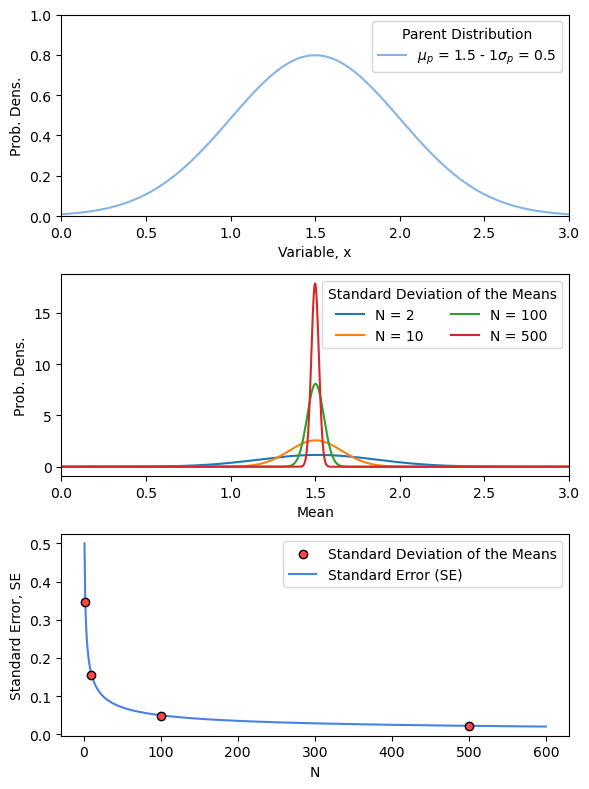

In [ ]:
import numpy as np  # untuk operasi numerik (array, perhitungan)
import scipy.stats as stats # untuk distribusi statistik (normal, dll)
import matplotlib.pyplot as plt  # untuk membuat grafik

mean_value = 1.5 # nilai mean (rata-rata distribusi)
std_dev = 0.5  # standar deviasi distribusi
dist = stats.norm(loc=mean_value, scale=std_dev)  # membuat objek distribusi normal (mean & std tertentu)
x = np.linspace(0, 3, 1000)  # membuat 1000 titik dari 0 sampai 3 (untuk kurva)
fig = plt.figure(figsize=(6,8)) # membuat figure ukuran 6x8 inci

# Distribution of the Random Variable based on the normal PDF
pdf = dist.pdf(x)  # menghitung nilai PDF distribusi normal
ax1 = fig.add_subplot(3, 1, 1)  # subplot 1 (3 baris, 1 kolom, posisi 1)
ax1.plot(x, pdf, color='#84b4e8', label =r'$\mu_p$ = 1.5 - 1$\sigma_p$ = 0.5') # menggambar kurva distribusi normal
ax1.set_xlim(0,3) # batas sumbu X
ax1.set_ylim(0,1) # batas sumbu Y
ax1.set_xlabel('Variable, x')
ax1.set_ylabel('Prob. Dens.')
ax1.legend(title = 'Parent Distribution') # legenda untuk distribusi awal (parent distribution)

# Dependence of the SE on the Central Limit Theorem
ax2 = fig.add_subplot(3, 1, 2) # subplot 2
std_of_the_mean = []    # list untuk menyimpan std dari mean
ns = [2, 10, 100, 500] # jumlah sampel (N)

for n in ns: # looping untuk tiap ukuran sampel
    # Mean Estimation Based on 1000 attempts using N values
    mean_dist = [] # list untuk menyimpan hasil rata-rata
    for _ in range(1000): # 1000 percobaan (simulasi)
        mean_dist.append(dist.rvs(size=n).mean())  # ambil n data acak → hitung mean → simpan
    mean_dist = np.array(mean_dist) # ubah ke array numpy
    std_of_the_mean.append(mean_dist.std()) # simpan standar deviasi dari distribusi mean
    normal = stats.norm(loc=mean_dist.mean(), scale=mean_dist.std()) # membuat distribusi normal dari mean hasil simulasi
    ax2.plot(x, normal.pdf(x), label='N = ' + str(n))  # plot distribusi mean untuk tiap N
ax2.set_xlim(0, 3) # batas sumbu X
ax2.set_xlabel('Mean')
ax2.set_ylabel('Prob. Dens.')
ax2.legend(title='Standard Deviation of the Means', ncol=2)  # legenda untuk tiap N  

# SE estimates and the empirically derived std of the Means
ax3 = fig.add_subplot(3, 1, 3) # subplot 3
ax3.scatter(ns, std_of_the_mean, color='#ff464a', edgecolor='#000000', label='Standard Deviation of the Means', zorder = 1) # plot hasil simulasi (std dari mean terhadap N)
n1 = np.linspace(1, 600, 600) # membuat rentang nilai N dari 1 sampai 600
se = std_dev / np.sqrt(n1) # rumus Standard Error (SE) = sigma / sqrt(n)
ax3.plot(n1 , se, c='#4881e9', label='Standard Error (SE)', zorder=0) # plot kurva teoritis SE
ax3.set_xlabel('N') # label sumbu X
ax3.set_ylabel('Standard Error, SE')
ax3.legend()
fig.tight_layout()  # merapikan layout grafik





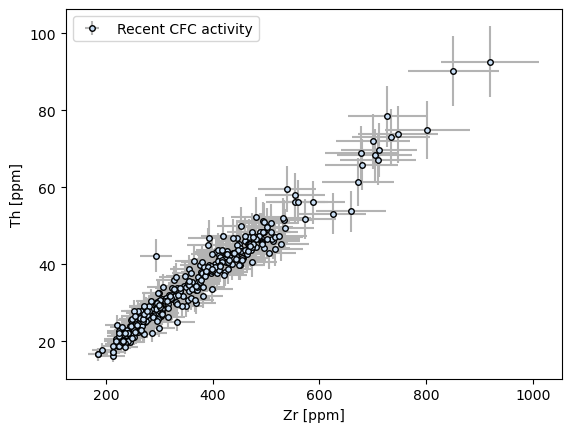

In [ ]:
import pandas as pd  # untuk membaca dan mengolah data (Excel)
import matplotlib.pyplot as plt # untuk membuat grafik

my_dataset1 = pd.read_excel('Smith_glass_post_NYT_data.xlsx', sheet_name='Supp_traces') # membaca data dari file Excel pada sheet 'Supp_traces'

x = my_dataset1.Zr # mengambil data Zr sebagai sumbu X
y = my_dataset1.Th # mengambil data Th sebagai sumbu Y
dx = my_dataset1.Zr * 0.1 # error pada sumbu X (10% dari nilai Zr)
dy = my_dataset1.Th * 0.1 # error pada sumbu Y (10% dari nilai Th)

fig, ax = plt.subplots() # membuat figure dan axis
ax.errorbar(x, y, xerr=dx, yerr=dy, marker='o', markersize=4, linestyle='', color='#c7ddf4', markeredgecolor='k', ecolor='0.7', label='Recent CFC activity')
# membuat plot dengan error bar:
# xerr → error horizontal
# yerr → error vertikal
# marker → bentuk titik
# linestyle='' → tanpa garis penghubung
# ecolor → warna garis error

ax.set_xlabel('Zr [ppm]')
ax.set_ylabel('Th [ppm]')
ax.legend(loc='upper left') # menampilkan legenda di kiri atas



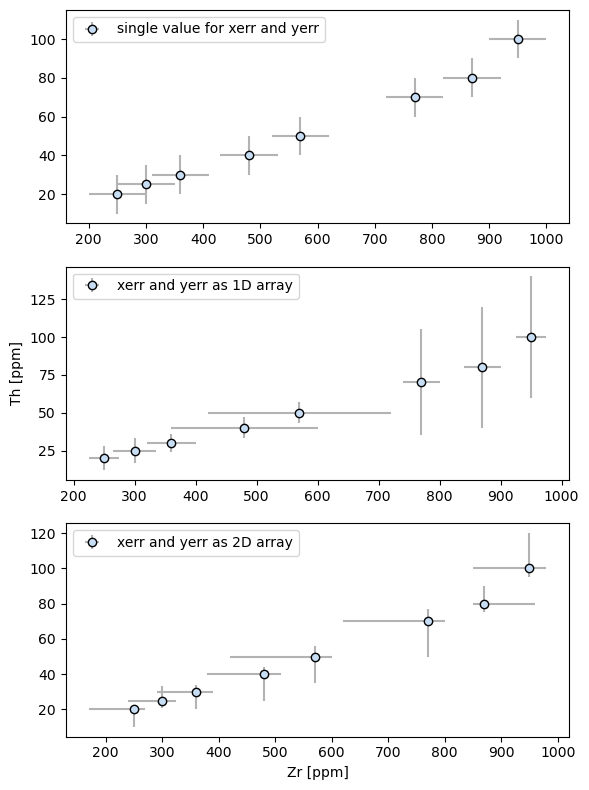

In [ ]:
import numpy as np # untuk operasi numerik (array)
import matplotlib.pyplot as plt # untuk membuat grafik

x = np.array([250,300,360,480,570,770,870,950]) # data sumbu X (misalnya Zr)
y = np.array([20,25,30,40,50,70,80,100]) # data sumbu Y (misalnya Th)


fig = plt.figure(figsize=(6,8)) # membuat figure ukuran 6x8 inci

# xerr and yerr reported as single value
dx = 50  # error konstan untuk semua titik di sumbu X
dy = 10  # error konstan untuk semua titik di sumbu Y
ax1 = fig.add_subplot(3,1,1) # subplot 1 (3 baris, 1 kolom, posisi 1)
ax1.errorbar(x, y, xerr=dx, yerr=dy, marker='o', markersize=6, linestyle = '', color='#c7ddf4', markeredgecolor='k', ecolor='0.7', label='single value for xerr and yerr') # error bar dengan nilai error yang sama untuk semua data
ax1.legend(loc='upper left')  # menampilkan legenda

# xerr and yerr reported as 1D array
dx = np.array([25,35,40,120,150,30,30,25]) # error berbeda untuk tiap titik (sumbu X)
dy = np.array([8,8,6,7,7,35,40,40])# error berbeda untuk tiap titik (sumbu Y)

ax2 = fig.add_subplot(3,1,2) # subplot 2
ax2.errorbar(x, y, xerr=dx, yerr=dy, marker='o', markersize=6, linestyle = '', color='#c7ddf4', markeredgecolor='k', ecolor='0.7', label='xerr and yerr as 1D array') # error bar dengan nilai error berbeda tiap titik
ax2.set_ylabel('Th [ppm]')
ax2.legend(loc='upper left')

# xerr and yerr reported as 2D array
dx = np.array([[80,60,70,100,150,150,20,100],[20,25,30,30,30,30,90,30]])
# error asimetris pada sumbu X:
# baris pertama = error ke kiri
# baris kedua = error ke kanan

dy = np.array([[10,4,10,15,15,20,5,5],[2,8,4,4,6,7,10,20]])
# error asimetris pada sumbu Y:
# baris pertama = error ke bawah
# baris kedua = error ke atas


ax3 = fig.add_subplot(3,1,3)  # subplot 3
ax3.errorbar(x, y, xerr=dx, yerr=dy, marker='o', markersize=6, linestyle = '', color='#c7ddf4', markeredgecolor='k', ecolor='0.7',  label='xerr and yerr as 2D array') # error bar asimetris (panjang error kiri ≠ kanan, atas ≠ bawah)
ax3.set_xlabel('Zr [ppm]')
ax3.legend(loc='upper left')

fig.tight_layout() # merapikan layout grafik

Text(0, 0.5, 'Th [ppm]')

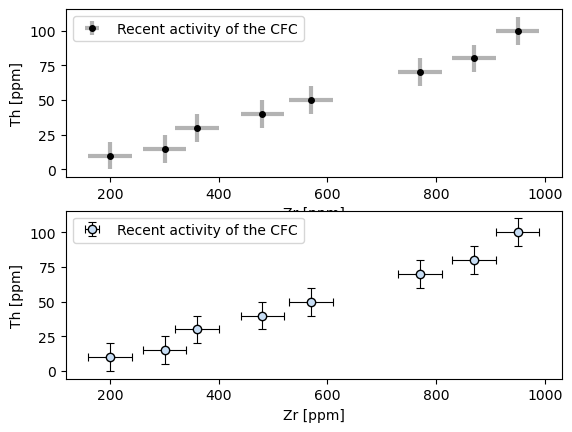

In [ ]:
import numpy as np  # untuk operasi numerik (array)
import matplotlib.pyplot as plt # untuk membuat grafik

x = np.array([200, 300, 360, 480, 570, 770, 870, 950]) # data sumbu X
y = np.array([10, 15, 30, 40, 50, 70, 80, 100]) # data sumbu Y
dx = 40    # error konstan pada sumbu X
dy = 10 # error konstan pada sumbu Y

fig = plt.figure()# membuat figure
ax1 = fig.add_subplot(2, 1, 1) # subplot 1 (2 baris, 1 kolom, posisi 1)
ax1.errorbar(x, y, xerr=dx, yerr=dy, marker='o', markersize=4, linestyle='', color='k',  ecolor='0.7', elinewidth=3, capsize=0, label='Recent activity of the CFC')
# errorbar dengan gaya:
# color='k' → warna titik hitam
# ecolor → warna garis error abu-abu
# elinewidth=3 → garis error tebal
# capsize=0 → tanpa garis penutup (cap) di ujung error

ax1.legend(loc='upper left')
ax1.set_xlabel('Zr [ppm]')
ax1.set_ylabel('Th [ppm]')

ax2 = fig.add_subplot(2,1,2)  # subplot 2
ax2.errorbar(x, y, xerr=dx, yerr=dy, marker='o', markersize=6, linestyle='', color='#c7ddf4', markeredgecolor='k', ecolor='k', elinewidth = 0.8, capthick=0.8, capsize=3, label='Recent activity of the CFC')
# errorbar dengan gaya berbeda:
# markersize=6 → titik lebih besar
# markeredgecolor='k' → tepi titik hitam
# ecolor='k' → warna error hitam
# elinewidth=0.8 → garis error lebih tipis
# capthick → ketebalan garis penutup (cap)
# capsize=3 → panjang garis penutup di ujung error

ax2.legend(loc='upper left')
ax2.set_xlabel('Zr [ppm]')
ax2.set_ylabel('Th [ppm]')

Text(0, 0.5, 'Th [ppm]')

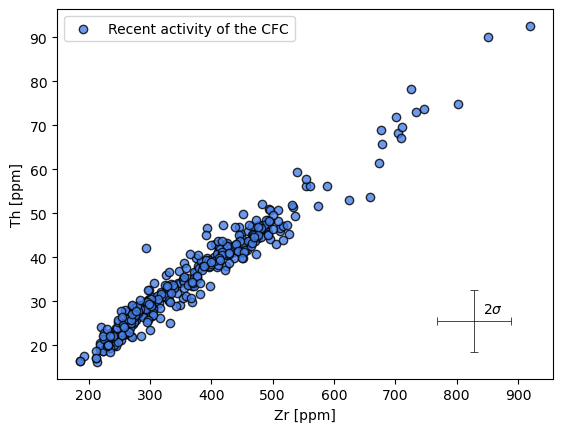

In [ ]:
import pandas as pd    # untuk membaca dan mengolah data (Excel)
import matplotlib.pyplot as plt # untuk membuat grafik
 

def plot_errorbar(x,y, dx, dy, xoffset, yoffset, text, ax):  # fungsi untuk menambahkan error bar + teks keterangan
    ax.errorbar(x,y, xerr=dx, yerr=dy, marker='', linestyle = '', elinewidth = .5, capthick=0.5,  ecolor='k', capsize=3)  # menggambar error bar saja (tanpa titik/marker)
    ax.text(x + xoffset, y + yoffset, text) # menambahkan teks di dekat error bar

my_dataset1 = pd.read_excel('Smith_glass_post_NYT_data.xlsx', sheet_name='Supp_traces') # membaca data dari file Excel

x = my_dataset1.Zr # data sumbu X (Zr)
y = my_dataset1.Th # data sumbu Y (Th)

dx = 60  # besar error pada sumbu X
dy = 7 # besar error pada sumbu Y

errorbar_x = x.max() - x.max() * 0.1 # posisi error bar di sumbu X (dekat nilai maksimum, dikurangi 10%)
errorbar_y = y.min() + y.max() * 0.1 # posisi error bar di sumbu Y (dari bawah + 10% rentang)

fig, ax1 = plt.subplots()  # membuat figure dan axis
ax1.scatter(x, y, marker='o', color='#4881e9', edgecolor='k', alpha=0.8, label='Recent activity of the CFC') # scatter plot data utama

plot_errorbar(errorbar_x, errorbar_y, dx, dy, dx/4, dy/4, r'2$\sigma$', ax1) # memanggil fungsi untuk menampilkan contoh error bar + label "2σ"

ax1.legend(loc='upper left')  # menampilkan legenda
ax1.set_xlabel('Zr [ppm]')
ax1.set_ylabel('Th [ppm]')


In [ ]:
import numpy as np   # untuk operasi numerik (akar, pangkat, dll)

def sum_ab(a, b, sigma_a, sigma_b): # fungsi untuk penjumlahan dua besaran dengan propagasi ketidakpastian
    z = a + b  # hasil penjumlahan nilai a dan b
    sigma_z = np.sqrt(sigma_a**2 + sigma_b**2)
    # propagasi error untuk penjumlahan:
    # σz = √(σa² + σb²)
    
    return z, sigma_z  # mengembalikan hasil dan errornya

def division_ab(a, b, sigma_a, sigma_b): # fungsi untuk pembagian dua besaran dengan propagasi ketidakpastian
    z = a / b # hasil pembagian a dibagi b
    sigma_z = z * np.sqrt((sigma_a/a)**2 + (sigma_b/b)**2)
     # propagasi error untuk pembagian:
    # σz/z = √((σa/a)² + (σb/b)²)
    return z, sigma_z # mengembalikan hasil dan errornya


In [ ]:
import sympy as sym # untuk komputasi simbolik (turunan, aljabar, dll)

# mendefinisikan variabel simbolik
a, b, sigma_a, sigma_b = sym.symbols("a b sigma_a sigma_b")
# a, b = variabel utama
# sigma_a, sigma_b = ketidakpastian (error)

def symbolic_error_prop(func, val_a, val_sigma_a, val_b=0, val_sigma_b=0): # fungsi untuk propagasi error secara simbolik menggunakan SymPy
    
    z = sym.lambdify([a,b],func, 'numpy') # mengubah fungsi simbolik menjadi fungsi numerik (agar bisa dihitung)
    sigma_z = sym.lambdify([a, b, sigma_a, sigma_b], sym.sqrt((sym.diff(func, a)**2 * sigma_a**2)+(sym.diff(func, b)**2 * sigma_b**2)), 'numpy')
    # menghitung propagasi error secara simbolik:
    # σz = √((∂f/∂a)² σa² + (∂f/∂b)² σb²)
    # lalu dikonversi menjadi fungsi numerik dengan lambdify
    
    val_z = z(a=val_a, b=val_b) # menghitung nilai fungsi utama (z) dengan input angka
    val_sigma_z = sigma_z(a=val_a, b=val_b, sigma_a=val_sigma_a, sigma_b=val_sigma_b)  # menghitung nilai ketidakpastian (error) dari z
    
    return val_z, val_sigma_z # mengembalikan hasil dan error

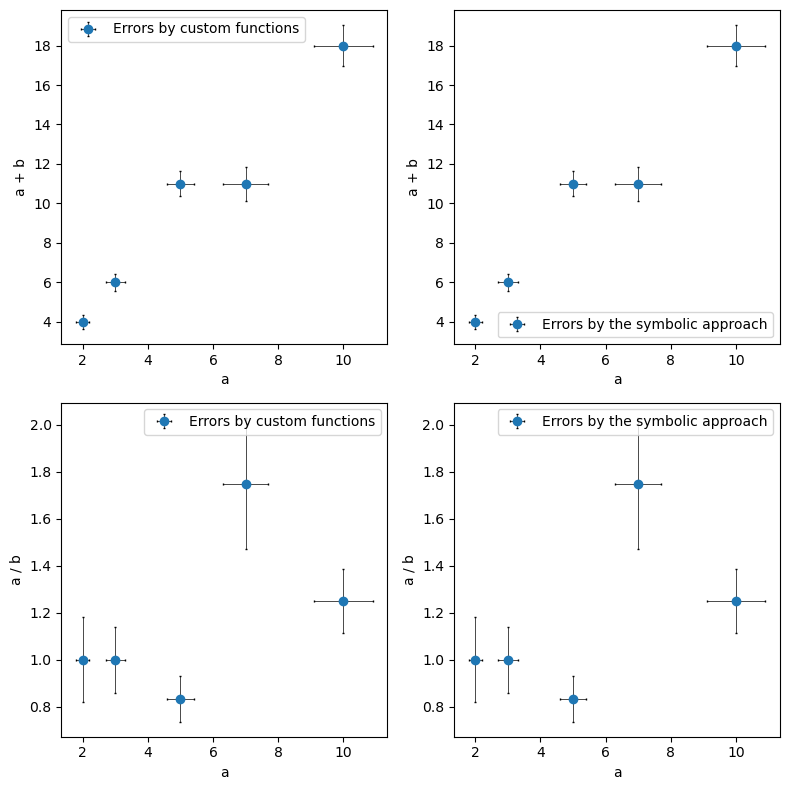

In [ ]:
my_a = np.array([2, 3, 5, 7, 10]) # data nilai a
my_sigma_a = np.array([0.2, 0.3, 0.4, 0.7, 0.9])  # ketidakpastian (error) untuk a
my_b = np.array([2, 3, 6, 4, 8]) # data nilai b
my_sigma_b = np.array([0.3, 0.3, 0.5, 0.5, 0.5]) # ketidakpastian (error) untuk b

# errors propagated using custom functions
my_sum_ab_l, my_sigma_sum_ab_l = sum_ab(a=my_a, b=my_b, sigma_a=my_sigma_a, sigma_b=my_sigma_b) # menghitung (a + b) dan errornya menggunakan fungsi manual (custom)
my_division_ab_l, my_sigma_division_ab_l = division_ab(a=my_a, b=my_b, sigma_a=my_sigma_a, sigma_b=my_sigma_b) # menghitung (a / b) dan errornya menggunakan fungsi manual (custom)

# errors propagated using the symbolic approach
my_sum_ab_s, my_sigma_sum_ab_s = symbolic_error_prop(func=a+b, val_a=my_a, val_sigma_a=my_sigma_a, val_b=my_b, val_sigma_b=my_sigma_b)  # menghitung (a + b) dan errornya menggunakan metode simbolik (SymPy)
my_division_ab_s, my_sigma_division_ab_s = symbolic_error_prop(func=a/b, val_a=my_a, val_sigma_a=my_sigma_a, val_b=my_b, val_sigma_b=my_sigma_b) # menghitung (a / b) dan errornya menggunakan metode simbolik (SymPy)

fig = plt.figure(figsize=(8, 8)) # membuat figure ukuran 8x8 inci
ax1 = fig.add_subplot(2, 2, 1)# subplot 1 (baris 1 kolom 1)
ax1.errorbar(x=my_a, y=my_sum_ab_l, xerr=my_sigma_a, yerr=my_sigma_sum_ab_l, linestyle='', marker='o', ecolor='k', elinewidth=0.5, capsize=1, label='Errors by custom functions') # errorbar hasil penjumlahan (metode custom)
ax1.set_xlabel('a') # label sumbu X
ax1.set_ylabel('a + b')
ax1.legend()

ax2 = fig.add_subplot(2, 2, 2) # subplot 2
ax2.errorbar(x=my_a, y=my_sum_ab_s, xerr=my_sigma_a, yerr=my_sigma_sum_ab_s, linestyle='', marker='o', ecolor='k', elinewidth=0.5, capsize=1, label='Errors by the symbolic approach') # errorbar hasil penjumlahan (metode simbolik)
ax2.set_xlabel('a')
ax2.set_ylabel('a + b')
ax2.legend()

ax3 = fig.add_subplot(2, 2, 3) # subplot 3
ax3.errorbar(x=my_a, y=my_division_ab_l, xerr=my_sigma_a, yerr=my_sigma_division_ab_l, linestyle='', marker='o', ecolor='k', elinewidth=0.5, capsize=1, label='Errors by custom functions') # errorbar hasil pembagian (metode custom)
ax3.set_xlabel('a')
ax3.set_ylabel('a / b')
ax3.legend()

ax4 = fig.add_subplot(2,2,4) # subplot 4
ax4.errorbar(x=my_a, y=my_division_ab_s, xerr=my_sigma_a, yerr=my_sigma_division_ab_s, linestyle='', marker ='o', ecolor='k', elinewidth=0.5, capsize=1, label='Errors by the symbolic approach') # errorbar hasil pembagian (metode simbolik)
ax4.set_xlabel('a')
ax4.set_ylabel('a / b')
ax4.legend()
fig.tight_layout()# merapikan layout agar tidak tumpang tindih

Text(0.5, 0, 'La [ppm]')

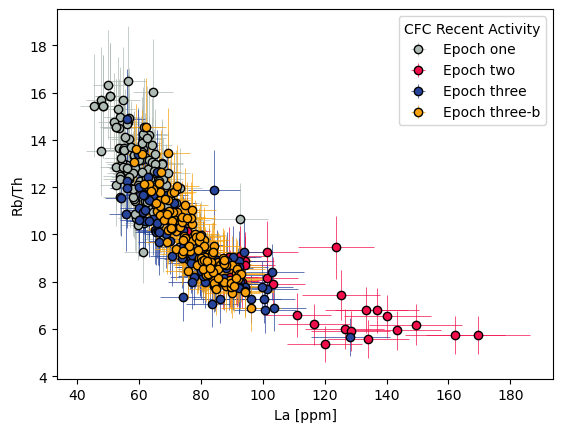

In [ ]:
import pandas as pd # library untuk mengolah data tabel (Excel, CSV)
import matplotlib.pyplot as plt # library untuk membuat grafik/plot
import sympy as sym # library untuk perhitungan simbolik (turunan, aljabar)

a, b, sigma_a, sigma_b = sym.symbols("a b sigma_a sigma_b") # mendefinisikan variabel simbolik untuk perhitungan error propagation

def symbolic_error_prop(func, val_a, val_sigma_a,  val_b=0,  val_sigma_b=0): # fungsi untuk menghitung nilai fungsi dan propagasi error secara simbolik
    
    z = sym.lambdify([a, b], func, 'numpy') # mengubah ekspresi simbolik menjadi fungsi numerik (bisa dipakai dengan numpy/pandas)
    sigma_z = sym.lambdify([a, b, sigma_a, sigma_b], sym.sqrt((sym.diff(func, a)**2 * sigma_a**2)+(sym.diff(func,b)**2 * sigma_b**2)), 'numpy') # menghitung nilai fungsi dengan data input
    val_z = z(a=val_a, b=val_b)  # menghitung nilai fungsi utama (misalnya Rb/Th) dengan data a dan b
    val_sigma_z = sigma_z(a=val_a, b=val_b, sigma_a=val_sigma_a, sigma_b=val_sigma_b) # menghitung ketidakpastian (error propagation) dari fungsi z
    
    return val_z, val_sigma_z # mengembalikan nilai hasil perhitungan dan error-nya

my_dataset = pd.read_excel('Smith_glass_post_NYT_data.xlsx', sheet_name='Supp_traces') # membaca data dari file Excel pada sheet "Supp_traces"

ratio_y, sigma_ratio_y = symbolic_error_prop(a/b, val_a=my_dataset.Rb, val_sigma_a=my_dataset.Rb*0.1, val_b=my_dataset.Th,  val_sigma_b=my_dataset.Th*0.1)
ratio_y, sigma_ratio_y = symbolic_error_prop 
#  a/b,                                # fungsi yang dihitung: rasio Rb terhadap Th
# val_a=my_dataset.Rb,                # data a = Rb
# val_sigma_a=my_dataset.Rb*0.1,      # error Rb diasumsikan 10%
# val_b=my_dataset.Th,                # data b = Th
# val_sigma_b=my_dataset.Th*0.1       # error Th diasumsikan 10%
# menghitung nilai rasio Rb/Th beserta ketidakpastiannya untuk semua data

my_dataset['Rb_Th'] = ratio_y# menyimpan hasil rasio Rb/Th ke dalam kolom baru dataframe
my_dataset['Rb_Th_1s'] = sigma_ratio_y  # menyimpan hasil error (1 sigma) ke dalam kolom baru dataframe

epochs = ['one','two','three','three-b'] # daftar kategori epoch (kelompok data)
colors = ['#afbbb5', '#f10e4a', '#27449c', '#f9a20e'] # warna berbeda untuk tiap epoch pada grafik

fig, ax = plt.subplots()# membuat figure dan axis untuk plotting
for epoch, color in zip(epochs, colors):  # looping setiap epoch dan warna
    my_data = my_dataset[(my_dataset.Epoch == epoch)]  # filter data berdasarkan epoch tertentu
    ax.errorbar(x=my_data.La, y=my_data.Rb_Th, xerr=my_data.La*0.1, yerr=my_data.Rb_Th_1s, linestyle='', markerfacecolor= color, markersize=6, marker='o', markeredgecolor='k', ecolor=color, elinewidth=0.5, capsize=0, label="Epoch " + epoch)
# x=my_data.La,                 # sumbu X = konsentrasi La (ppm)
# y=my_data.Rb_Th,              # sumbu Y = rasio Rb/Th
# xerr=my_data.La*0.1,          # error X diasumsikan 10%
#  yerr=my_data.Rb_Th_1s,        # error Y dari propagasi error
# linestyle='',                 # tanpa garis penghubung antar titik
#  markerfacecolor=color,        # warna isi marker
#  markersize=6,                 # ukuran titik
#  marker='o',                   # bentuk marker bulat
# markeredgecolor='k',          # warna tepi marker hitam
# ecolor=color,                 # warna error bar
#   elinewidth=0.5,              # ketebalan error bar
#  capsize=0,                   # tanpa ujung "cap" pada error bar
#  label="Epoch " + epoch        # label untuk legend

ax.legend(title='CFC Recent Activity') # menampilkan legenda pada grafik (keterangan tiap data/epoch)
ax.set_ylabel('Rb/Th')
ax.set_xlabel('La [ppm]')


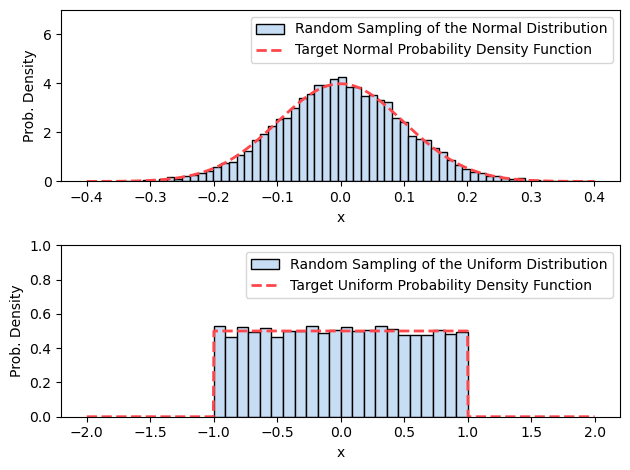

In [ ]:
import numpy as np  # library numerik untuk array dan probabilitas
import matplotlib.pyplot as plt  # library untuk membuat grafik

def normal_pdf(x, mu, sigma): # fungsi probability density function (PDF) distribusi normal
    pdf = 1/(sigma * np.sqrt(2*np.pi)) * np.exp(-(x-mu)**2 / (2*sigma**2))
    return pdf # mengembalikan nilai PDF normal

def unifrom_pdf(x, a, b): # fungsi probability density function (PDF) distribusi uniform
    pdf = np.piecewise(x, [(x>=a) & (x<=b), (x<a) & (x>b)], [1/(b-a), 0])  # membuat PDF distribusi uniform: nilai konstan 1/(b-a) di dalam interval, selain itu 0
    return pdf # mengembalikan nilai PDF uniform

# Random sampling of a normal distribution
my_mu, my_sigma = 0, 0.1 # mean and standard deviation # mean dan standar deviasi distribusi normal
sn = np.random.default_rng().normal(loc=my_mu, scale=my_sigma, size=10000) # membuat 10.000 data acak dari distribusi normal

fig = plt.figure() # membuat figure untuk plot
ax1 = fig.add_subplot(2, 1, 1) # subplot pertama (atas)
ax1.hist(sn, density=True, bins='auto', edgecolor='k', color='#c7ddf4', label='Random Sampling of the Normal Distribution') # histogram data sampling normal (dinormalisasi jadi PDF)
my_xn = np.linspace(my_mu - 4 * my_sigma, my_mu + 4 * my_sigma, 1000) # membuat rentang x untuk kurva PDF normal
my_yn = normal_pdf(x=my_xn, mu=my_mu, sigma=my_sigma) # menghitung PDF normal teoritis
ax1.plot(my_xn, my_yn,linewidth=2, linestyle='--', color='#ff464a', label='Target Normal Probability Density Function') # plot kurva PDF normal teoritis
ax1.set_ylim(0.0, 7.0) # batas sumbu Y
ax1.set_xlabel('x')
ax1.set_ylabel('Prob. Density')
ax1.legend()

# Random sampling of a uniform distribution
my_a, my_b = -1, 1 # lower and upper bound of the uniform distribution  # batas bawah dan atas distribusi uniform
su = np.random.default_rng().uniform(low=my_a, high=my_b, size=10000)
ax2 = fig.add_subplot(2, 1, 2) # subplot kedua (bawah)
ax2.hist(su, density=True, bins='auto', edgecolor='k', color='#c7ddf4', label='Random Sampling of the Uniform Distribution') # histogram data uniform (dinormalisasi jadi PDF)
my_xu = np.linspace(-2, 2, 1000) # rentang x untuk PDF uniform
my_yu = unifrom_pdf(x=my_xu, a=my_a, b=my_b) # menghitung PDF uniform teoritis
ax2.plot(my_xu, my_yu, linewidth=2, linestyle='--', color='#ff464a', label='Target Uniform Probability Density Function') # plot PDF uniform teoritis
ax2.set_ylim(0, 1) # batas sumbu Y
ax2.set_xlabel('x') 
ax2.set_ylabel('Prob. Density')
ax2.legend()

fig.tight_layout()  # merapikan layout agar tidak tumpang tindih


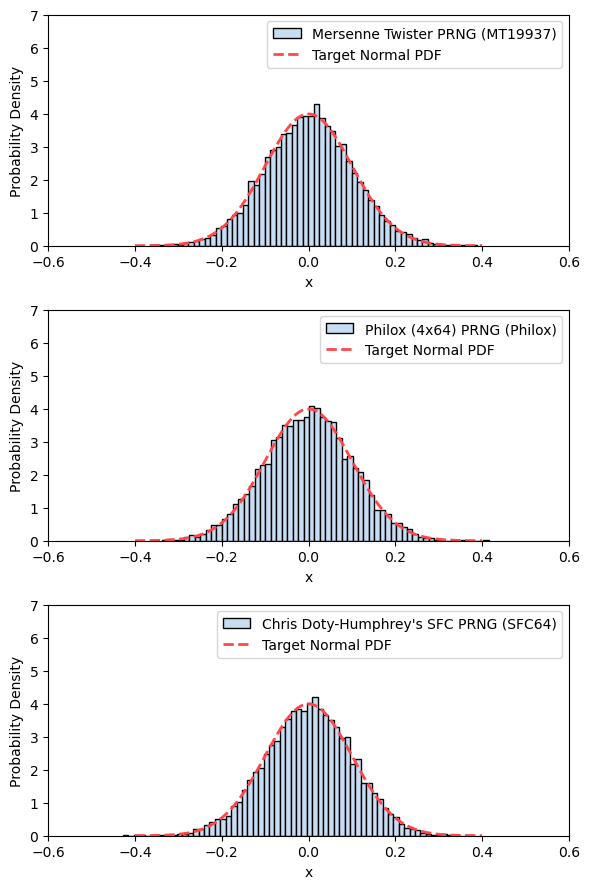

In [ ]:
import numpy as np # library numerik untuk array dan random generator
import matplotlib.pyplot as plt # library untuk plotting grafik

def normal_pdf(x, mu, sigma): # fungsi probability density function (PDF) distribusi normal
    pdf = 1/(sigma * np.sqrt(2 * np.pi)) * np.exp( - (x - mu)**2 / (2 * sigma**2)) # rumus PDF normal (Gaussian distribution)
    return pdf    # mengembalikan nilai PDF

fig = plt.figure(figsize=(6,9)) # membuat figure dengan ukuran 6x9 inch

# Random sampling of a normal distribution
my_mu, my_sigma = 0, 0.1 # mean and standard deviation # mean (μ) dan standar deviasi (σ)

bit_generators = [np.random.MT19937(), np.random.Philox(), np.random.SFC64()]
# np.random.MT19937(),   # generator Mersenne Twister
#  np.random.Philox(),    # generator Philox (parallel RNG)
#  np.random.SFC64()      # generator SFC64 (modern fast RNG)

names = ['Mersenne Twister PRNG (MT19937)', 'Philox (4x64) PRNG (Philox)', 'Chris Doty-Humphrey\'s SFC PRNG (SFC64)'] # label untuk tiap generator
indexes = [1,2,3] # posisi subplot (3 baris, 1 kolom)

for bit_generator, name, index in zip(bit_generators, names, indexes):   # loop untuk menjalankan 3 jenis random generator (MT19937, Philox, SFC64)
    sn = np.random.Generator(bit_generator).normal(loc = my_mu, scale = my_sigma, size = 10000) # membuat 10.000 data acak dari distribusi normal menggunakan generator berbeda
    ax = fig.add_subplot(3, 1, index) # membuat subplot 3 baris 1 kolom, posisi sesuai index (1-3)
    ax.hist(sn, density=True, bins='auto', edgecolor='k', color='#c7ddf4', label=name) # membuat histogram data normal (dinormalisasi jadi PDF)
    my_xn = np.linspace(my_mu - 4 * my_sigma, my_mu + 4 * my_sigma, 1000) # membuat rentang x untuk kurva PDF normal teoritis
    my_yn = normal_pdf(x=my_xn, mu=my_mu, sigma=my_sigma) # menghitung nilai PDF normal teoritis
    ax.plot(my_xn, my_yn, linewidth=2, linestyle='--', color='#ff464a', label ='Target Normal PDF') # menggambar kurva PDF normal untuk dibandingkan dengan histogram
    ax.set_ylim(0.0, 7.0)  # mengatur batas sumbu Y
    ax.set_xlim(my_mu - 6 * my_sigma, my_mu + 6 * my_sigma) # mengatur batas sumbu X
    ax.set_xlabel('x')
    ax.set_ylabel('Probability Density')
    ax.legend()

fig.tight_layout()


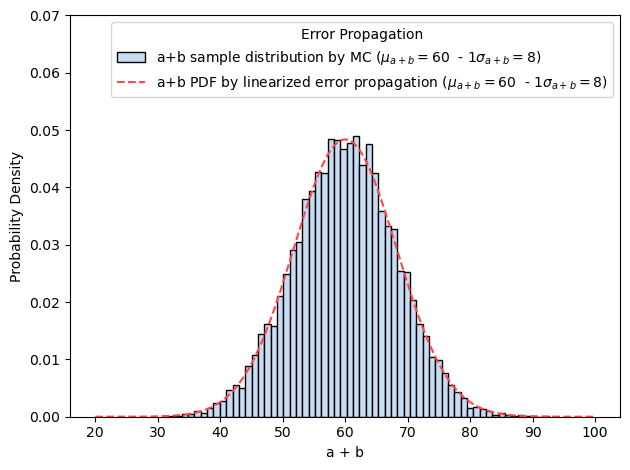

In [ ]:
import numpy as np  # library numerik untuk array dan simulasi
import matplotlib.pyplot as plt # library untuk plotting grafik

def gaussian(x, mean, std): # fungsi PDF distribusi Gaussian (normal)
    return 1/(np.sqrt(2*np.pi*std**2))*np.exp(-0.5*(((x - mean)**2)/(std**2)))   # rumus distribusi normal (Gaussian PDF)

my_a, my_sigma_a = 40, 8   # nilai a dan standar deviasi a
my_b, my_sigma_b = 20, 2  # nilai b dan standar deviasi b

n = 10000 # jumlah sampel Monte Carlo
a_normal = np.random.default_rng().normal(my_a, my_sigma_a, n) # generate 10.000 data acak untuk variabel a
b_normal = np.random.default_rng().normal(my_b, my_sigma_b, n)   # generate 10.000 data acak untuk variabel b

# Linearized Method
my_sum_ab_l, my_sigma_sum_ab_l = sum_ab(a=my_a, b=my_b, sigma_a=my_sigma_a, sigma_b=my_sigma_b) # menghitung mean dan error a+b menggunakan propagasi error (metode linear)
my_x = np.linspace(20, 100, 1000) # membuat range x untuk PDF hasil penjumlahan
my_sum_ab_PDF = gaussian(x=my_x, mean=my_sum_ab_l, std=my_sigma_sum_ab_l) # menghitung PDF Gaussian dari hasil linearized error propagation

# Monte Carlo estimation
my_sum_ab_mc =  a_normal + b_normal # menjumlahkan sampel a dan b (simulasi Monte Carlo)
my_sum_ab_mc_mean = my_sum_ab_mc.mean() # menghitung rata-rata hasil MC
my_sigma_sum_ab_mc_std = my_sum_ab_mc.std() # menghitung standar deviasi hasil MC
 
fig, ax = plt.subplots() # membuat figure dan axis
ax.hist(my_sum_ab_mc, bins='auto', color='#c7ddf4', edgecolor='k', density=True, label= r'a+b sample distribution by MC ($\mu_{a+b} = $' + "{:.0f}".format(my_sum_ab_mc_mean) + r'  - 1$\sigma_{a+b} = $' + "{:.0f}".format(my_sigma_sum_ab_mc_std) + ')') # histogram hasil Monte Carlo (distribusi a+b)
ax.plot(my_x, my_sum_ab_PDF, color='#ff464a', linestyle='--', label=r'a+b PDF by linearized error propagation ($\mu_{a+b} = $' + "{:.0f}".format(my_sum_ab_l) + r'  - 1$\sigma_{a+b} = $' + "{:.0f}".format(my_sigma_sum_ab_l) + ')') # kurva PDF hasil metode linearized (propagasi error)
ax.set_xlabel('a + b') # label sumbu X
ax.set_ylabel('Probability Density')
ax.legend(title='Error Propagation')
ax.set_ylim(0,0.07) # batas sumbu Y

fig.tight_layout() # merapikan layout agar tidak bertumpuk


